# Breakdown Voltage Computation (Reworked)


In [92]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Import packages

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append('../')
import pylars

In [94]:
import pylars.utils.input
import pylars.utils.output
from pylars.analysis.breakdown import *
from pylars.plotting.plotprocessed import *

## Setup the run

In [95]:
run_number = 1
main_data_path = '../kadev/data/'
F_amp = 1
ADC_model = 'v1724'

In [96]:
base_run = pylars.utils.input.run(
    run_number,
    main_data_path,
    F_amp,
    ADC_model,
)

### initiate processor

In [97]:
sigma_level = 2
baseline_samples = 14000

In [98]:
process = pylars.processing.rawprocessor.run_processor(
    base_run,
    'simple',
    sigma_level,
    baseline_samples,
)

### initiate dataset

In [99]:
temperature = 170
module = 0
channel = 'wf0'
processor = process

In [100]:
bvd = BV_dataset(
    base_run,
    temperature,
    module,
    channel,
    processor,
)

In [101]:
bvd.voltages = bvd.get_voltages_available()
print(f"Found voltages: \n {bvd.voltages}")
print(bvd.temp)

Found voltages: 
 [46.5 46.8 47.1 47.4 47.7 48.  48.3 48.6 48.9 49.2 49.5 49.8]
170


## Process Dataset

assuming the raw data is located at: main_data_path + "run" + run_number + "/data"

here eg. : "../kadev/data/run1/data"

as main_data_path = "../kadev/data/"
and run_number = 1

this processes the files and safes the processed data in the run directory as .hdf5 files.

If the processed files already exist you can skip the following cell and directly load the data.

In [102]:
for _voltage in bvd.voltages:
    print(f"Processing data for {_voltage} V: \n")
    
    df = process.process_datasets(
        'BV',
        _voltage,
        bvd.temp,
    )

    processed_data = pylars.utils.output.processed_dataset(
        base_run,
        'BV',
        _voltage,
        bvd.temp,
        base_run.main_data_path,
        process.hash,
    )
    processed_data.input_data(df)
    processed_data.save_data(type='hdf5')

Processing data for 46.5 V: 

Found 1 datasets. Ramping up processor!


Loading and processing datasets: 100%|██████████████████████████████████████| 1/1 [00:10<00:00, 10.14s/it]


Saved file to: ../kadev/data/run1/BV_170.00_46.50-mrqweiq.h5
Processing data for 46.8 V: 

Found 1 datasets. Ramping up processor!


Loading and processing datasets: 100%|██████████████████████████████████████| 1/1 [00:10<00:00, 10.90s/it]


Saved file to: ../kadev/data/run1/BV_170.00_46.80-mrqweiq.h5
Processing data for 47.1 V: 

Found 1 datasets. Ramping up processor!


...

Saved file to: ../kadev/data/run1/BV_170.00_49.20-mrqweiq.h5
Processing data for 49.5 V: 

Found 1 datasets. Ramping up processor!


Loading and processing datasets: 100%|██████████████████████████████████████| 1/1 [00:10<00:00, 10.74s/it]


Saved file to: ../kadev/data/run1/BV_170.00_49.50-mrqweiq.h5
Processing data for 49.8 V: 

Found 1 datasets. Ramping up processor!


Loading and processing datasets: 100%|██████████████████████████████████████| 1/1 [00:10<00:00, 10.56s/it]


Saved file to: ../kadev/data/run1/BV_170.00_49.80-mrqweiq.h5


In [103]:
bvd.load_processed_data()

Loading processed data for BV data at 170K: 100%|█████████████████████████| 12/12 [00:01<00:00, 11.16it/s]


An ugly look at the dataset can be seen with

In [128]:
bvd.data

{np.float64(46.5):         module channel  wf_number  pulse_number  n_pulses     area  length  \
 0            0     wf0          0             0         2   2330.0       4   
 1            0     wf0          0             1         2   1870.0       4   
 2            0     wf0          1             0         1     -0.0       1   
 3            0     wf0          2             0         1  13900.0      10   
 4            0     wf0          3             0         3     -0.0       1   
 ...        ...     ...        ...           ...       ...      ...     ...   
 161582       0     wf0      99998             2         5     -0.0       1   
 161583       0     wf0      99998             3         5     -0.0       1   
 161584       0     wf0      99998             4         5     -0.0       1   
 161585       0     wf0      99999             0         2     -0.0       1   
 161586       0     wf0      99999             1         2     -0.0       1   
 
         position  amplitude  
 

A more beautiful view of the datasets can be achieved by looking at it through the processed_dataset class which already displays the dataset tabularised.

In [125]:
processed_data.data

,module,channel,wf_number,pulse_number,n_pulses,area,length,position,amplitude
0,0,wf0,0,0,1,62760.0,9,15,12978.0
1,0,wf0,1,0,1,119150.0,9,15,12048.0
2,0,wf0,2,0,1,57840.0,8,15,12904.0
3,0,wf0,3,0,1,38780.0,9,16,13318.0
4,0,wf0,4,0,1,122840.0,9,14,12017.0
...,...,...,...,...,...,...,...,...,...
110992,0,wf0,99995,0,1,64450.0,9,14,12960.0
110993,0,wf0,99996,0,1,93000.0,10,14,12678.0
110994,0,wf0,99997,0,1,71090.0,13,14,13232.0
110995,0,wf0,99998,0,1,63565.0,12,13,13275.0


## Check a Waveform

In [105]:
check_waveform_of_voltage = bvd.voltages[0]

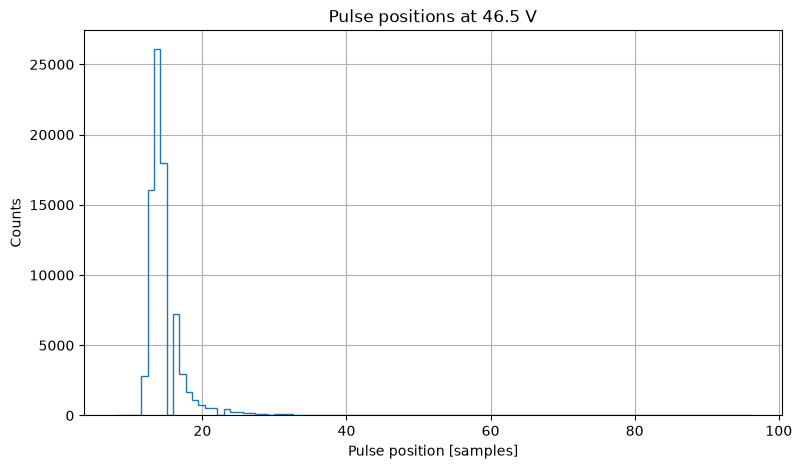

In [106]:
check_df = bvd.data[check_waveform_of_voltage]

plt.figure(figsize=(9,5))
plt.hist(
    check_df.loc[check_df["length"] > 3, "position"],
    bins = 100,
    histtype = "step",
)
plt.xlabel("Pulse position [samples]")
plt.ylabel("Counts")
plt.title(f"Pulse positions at {check_waveform_of_voltage} V")
plt.grid()
plt.show()

## Simple Breakdown Voltage Computation

This safes the fit plot in the "/figures" folder of the jupyter notebook location, which has to exist in the first place, and outputs the computed breakdown voltage, its error and the R^2 (goodness of fit) of the linear regression.

Since this is a simplified computation it doesn't include the real gain computation but rather computes the peak areas and treats their ratios as proportional to the gain (which is true but not 100 % accurate).

In [115]:
bv, bv_error, r2 = bvd.compute_BV_LED_simple(
    LED_position = 14,
    plot = True,
)
print(f"Computed breakdown voltage: {bv:.2f} +- {bv_error:.2f} V.")

Computed breakdown voltage: 46.38 +- 0.13 V.
